# Biography databases

Scholarly biographical dictionaries Cultura can be compared with: one biography downloaded from each (`building_scripts/dictionary_texts.py`).

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import polars as pl

ROOT = Path.cwd().resolve()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "5-annotations" / "building_scripts"))
from dictionary_texts import DB, DICTIONARIES, OUT

sys.path.insert(0, str(ROOT / "notebooks" / "notebooks_analysis"))
from style import show_table

texts = json.loads(OUT.read_text(encoding="utf-8"))
downloaded = {key: row for key, row in texts.items() if "text" in row and "pid" in DICTIONARIES[key]}
treccani = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "treccani_validation" / "treccani_texts.parquet")
labels = pl.DataFrame(duckdb.connect(str(DB), read_only=True).execute(
    "SELECT entity.qid AS wikidata_id, entity.label_en AS label FROM individual WHERE entity.qid IN (SELECT unnest(?)) AND entity.label_en IS NOT NULL",
    [treccani["wikidata_id"].to_list()]).fetchall(), schema=["wikidata_id", "label"], orient="row")
treccani_example = treccani.join(labels, on="wikidata_id").sort("wikidata_id").sample(1, seed=42).row(0, named=True)
print(f"Treccani example: {treccani_example['label']} ({treccani_example['wikidata_id']}), {treccani_example['dbi_url']}")
print(f"{len(DICTIONARIES)} dictionaries, {len(downloaded)} with a downloaded biography and a Wikidata identifier")

Treccani example: Anselm, Duke of Friuli (Q569615), https://www.treccani.it/enciclopedia/anselmo-di-nonantola-santo_(Dizionario-Biografico)/
21 dictionaries, 12 with a downloaded biography and a Wikidata identifier


## Overview table

In [2]:
REGIONS = {
    "treccani": "Italy",
    "deutsche_biographie": "German-speaking world", "oebl": "Austria-Hungary", "dwb": "Wales", "sbl": "Sweden",
    "nbl": "Norway", "dbl": "Denmark", "dcb": "Canada", "iranica": "Persia, Islamic East", "encykorea": "Korea",
    "sep": "Global / Philosophers", "mactutor": "Global / Mathematicians", "catholic_encyclopedia": "Global / Catholic Church",
}

overview = pl.DataFrame([
    {
        "Dictionary": DICTIONARIES[key]["name"],
        "Region / Topic": REGIONS[key],
        "Biography Example": row["label"],
        "Number of Characters": len(row["text"]),
    }
    for key, row in downloaded.items()
] + [{
    "Dictionary": "Dizionario Biografico degli Italiani (Treccani)",
    "Region / Topic": REGIONS["treccani"],
    "Biography Example": treccani_example["label"],
    "Number of Characters": len(treccani_example["text"]),
}]).sort("Dictionary")
assert overview["Dictionary"].is_unique().all() and overview["Biography Example"].null_count() == 0
overview.shape

(13, 4)

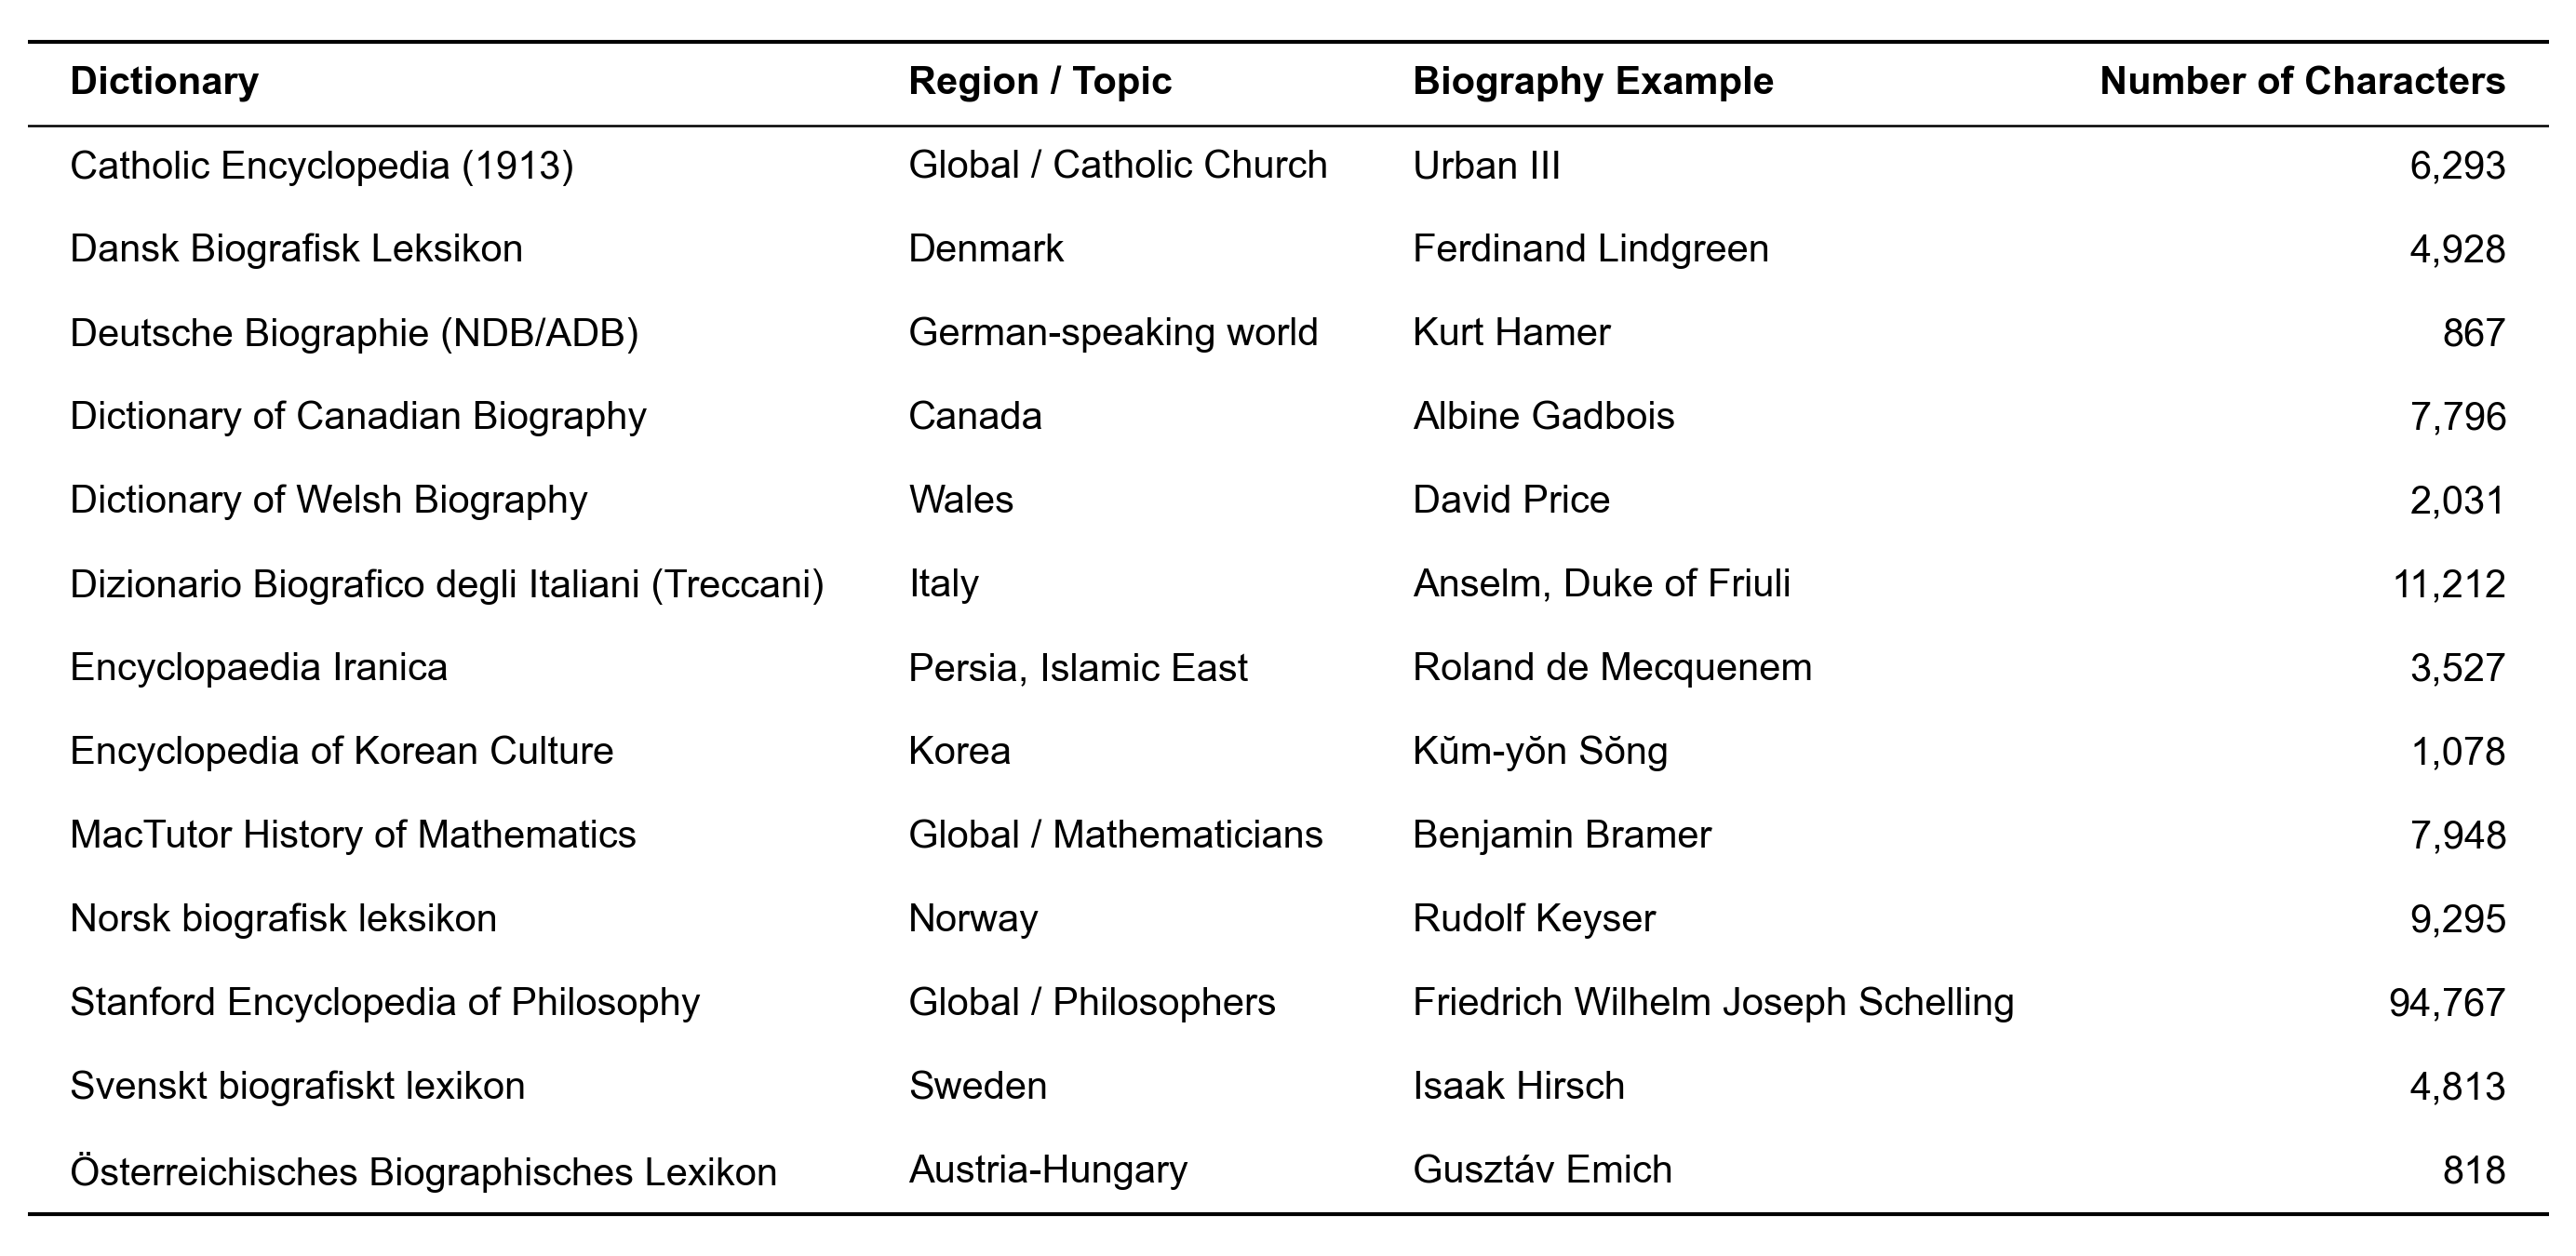

In [3]:
show_table(overview, font_size=10)

## Benchmark coverage

Cultura individuals covered by at least one dictionary, with an English label, a birth and a death year (`building_scripts/benchmark_population.py`). Region from the birthplace, else the country of citizenship, in present-day borders; century of birth.

In [4]:
population = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark_population.parquet")
NAMES = {key: dictionary["name"] for key, dictionary in DICTIONARIES.items()} | {"treccani": "Dizionario Biografico degli Italiani (Treccani)"}
PERIODS = [(-10_000, 500, "before 500"), (500, 1000, "500–999"), (1000, 1300, "1000–1299"), (1300, 1500, "1300–1499"),
           (1500, 1600, "1500s"), (1600, 1700, "1600s"), (1700, 1800, "1700s"), (1800, 1900, "1800s"), (1900, 3000, "1900s")]
REGION_ORDER = ["Western Europe", "Northern Europe", "Southern Europe", "Eastern Europe", "Middle East & North Africa",
                "South & Central Asia", "East Asia", "Southeast Asia", "Sub-Saharan Africa", "North America",
                "Latin America", "Oceania", "Other", "Unknown"]

period = pl.lit(None, dtype=pl.Utf8)
for low, high, label in reversed(PERIODS):
    period = pl.when((pl.col("birth_year") >= low) & (pl.col("birth_year") < high)).then(pl.lit(label)).otherwise(period)
people = population.unique("qid").with_columns(period=period)
assert people["period"].null_count() == 0
print(f"{len(population):,} dictionary entries, {len(people):,} individuals")

114,763 dictionary entries, 109,452 individuals


### Individuals per dictionary

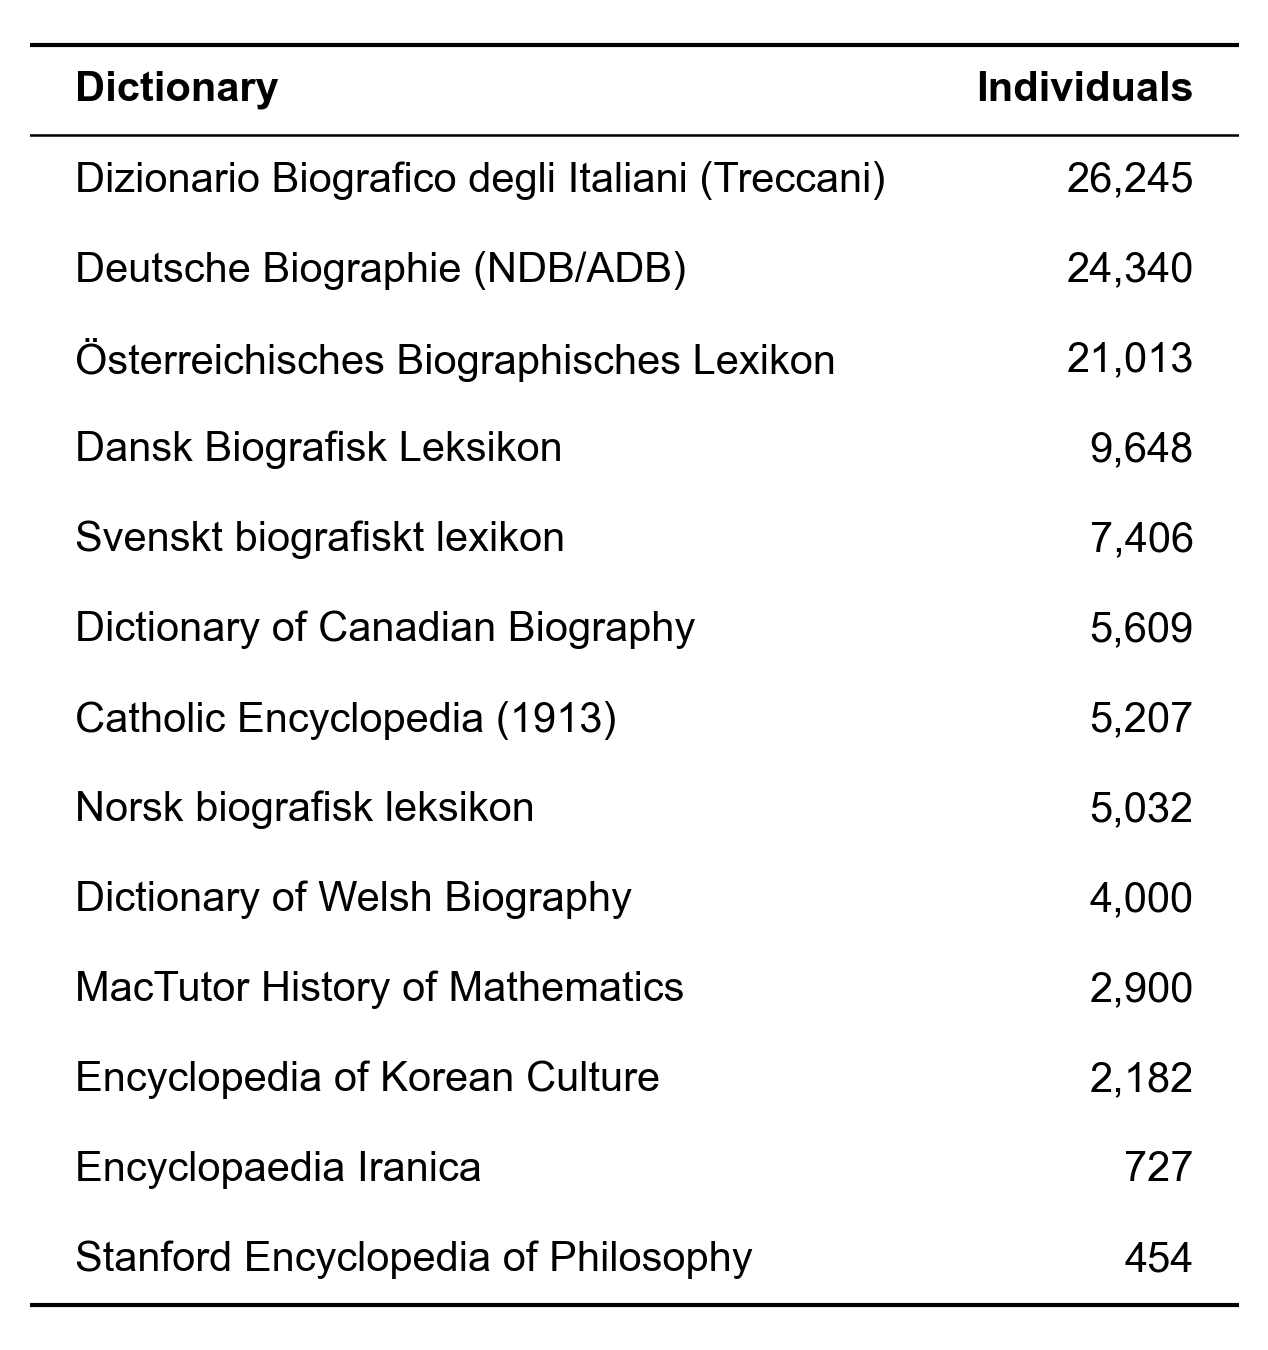

In [5]:
per_dictionary = (population.group_by("dictionary").agg(pl.col("qid").n_unique().alias("Individuals"))
    .with_columns(pl.col("dictionary").replace_strict(NAMES).alias("Dictionary"))
    .select("Dictionary", "Individuals").sort("Individuals", descending=True))
show_table(per_dictionary, font_size=10)

### Individuals per region and period of birth

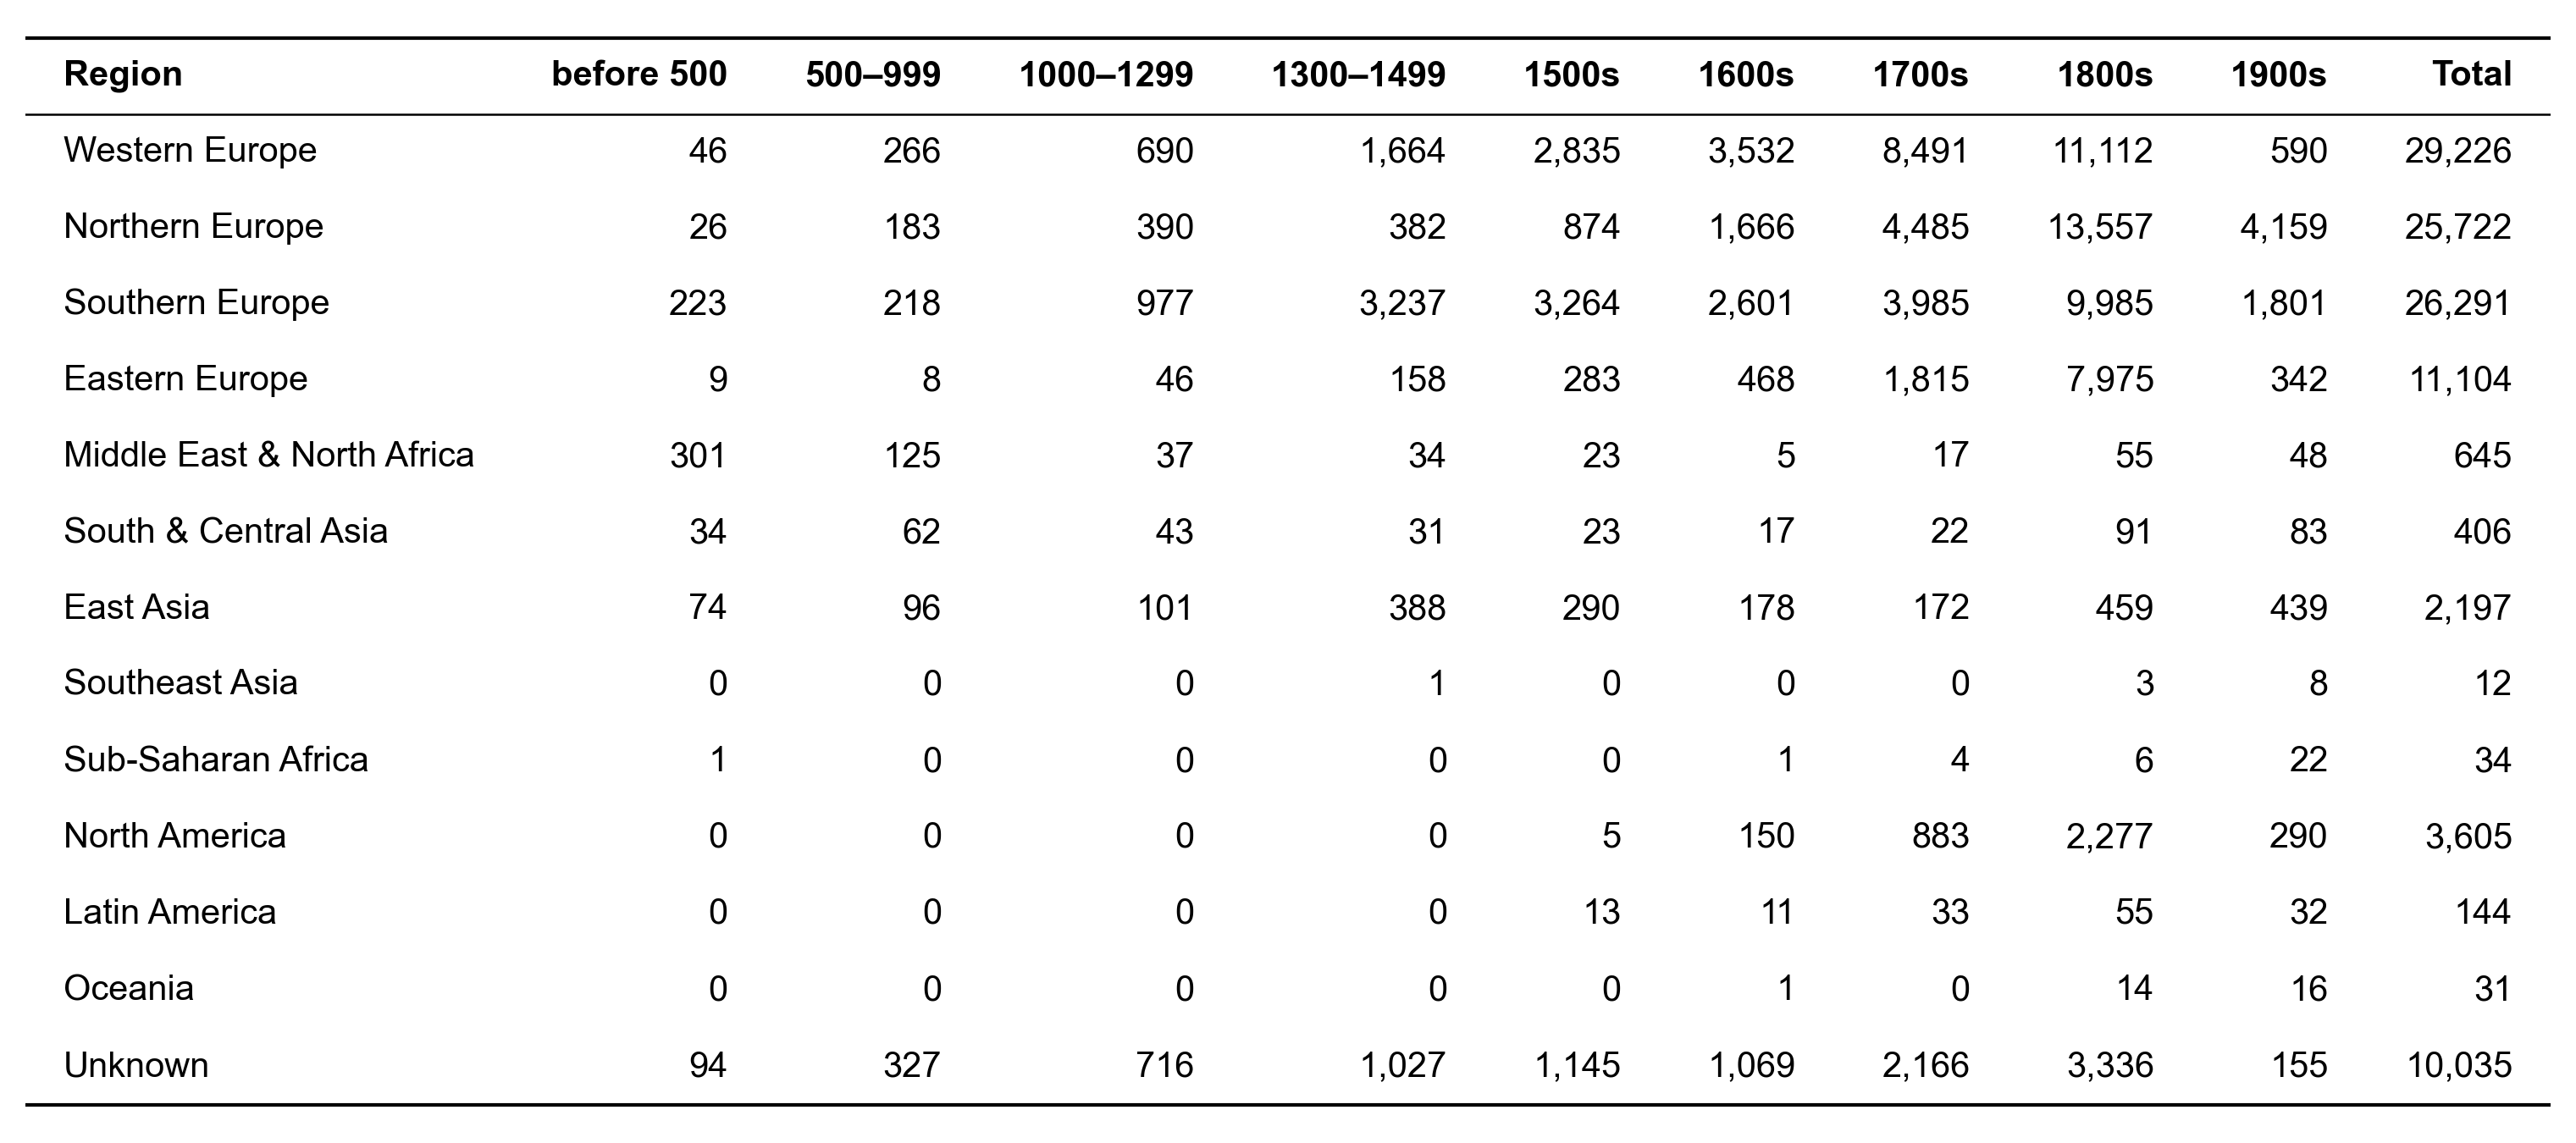

In [6]:
labels = [label for _, _, label in PERIODS]
per_region = (people.pivot(on="period", index="region", values="qid", aggregate_function="len")
    .with_columns(pl.col("region").replace_strict({r: i for i, r in enumerate(REGION_ORDER)}).alias("order"))
    .sort("order").fill_null(0))
per_region = per_region.select(pl.col("region").alias("Region"), *[pl.col(label) for label in labels if label in per_region.columns]).with_columns(
    Total=pl.sum_horizontal(*[pl.col(label) for label in labels if label in per_region.columns]))
show_table(per_region, font_size=10)